# Unsupervised anomaly detection with Local Outlier Factor (LOF)
## Example: synthetic machine data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler,RobustScaler

# Read data
using a url to a shared google drive

In [ ]:
import pandas as pd
option=2
if option==1:
  # easy
  url = "https://drive.google.com/uc?export=download&id=1-6nz0ldZcD6zflGE2QnExvfoMYaioOH4"
elif option==2:
  # hard
  url = "https://drive.google.com/uc?export=download&id=1lo7kzz6nGQYiM18dnN5dodgMUDmjym_g"


# Load the CSV into a DataFrame directly from the URL
df = pd.read_csv(url)

# Display the first few rows to confirm
df.head()

,temperature,vibrations,state,label
0,65.908897,5.092387,2.0,0.0
1,36.991467,10.778417,1.0,0.0
2,33.815246,6.019315,1.0,0.0
3,41.070469,6.131392,1.0,0.0
4,70.379023,2.322838,2.0,0.0


# Visualize the data

Text(0, 0.5, 'Vibrations')

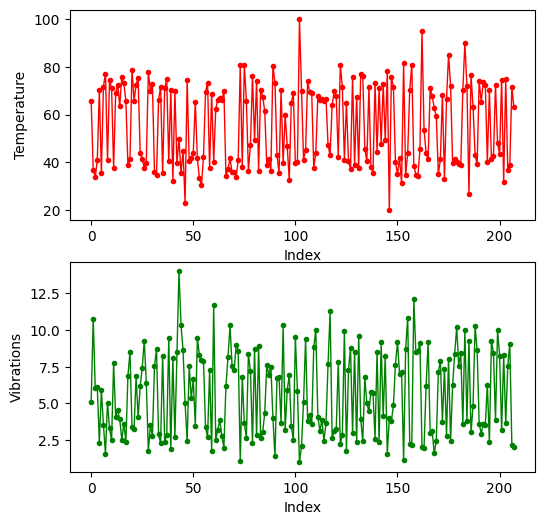

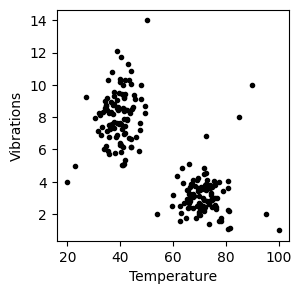

In [ ]:
# serial plots
fig, axes = plt.subplots(2, 1, figsize=(6, 6))

axes[0].set_xlabel("Index")
axes[0].set_ylabel("Temperature")
axes[0].plot(df['temperature'],'o-r',ms=3,lw=1)

axes[1].set_xlabel("Index")
axes[1].set_ylabel("Vibrations")
axes[1].plot(df['vibrations'],'o-g',ms=3,lw=1)

# scatter plot
plt.figure(figsize=(3,3))
plt.plot(df['temperature'],df['vibrations'],'ok',ms=3)
plt.xlabel('Temperature')
plt.ylabel('Vibrations')

# AD with LOF

## extract only the variables from the dataframe

In [ ]:
data = df[['temperature','vibrations']].copy().values

## run LOF with specific hyperparameters

In [ ]:
# Scale the data - important for better detection
scaler = RobustScaler()
data_scaled = scaler.fit_transform(data)

# define Hyperparameters n_neighbors and contamination_ratio
n_neighbors_value = 20
contamination_ratio = 0.05

# Run LOF
lof = LocalOutlierFactor(n_neighbors=n_neighbors_value, contamination=contamination_ratio)
# fit lof to the scaled data
lof.fit(data_scaled)
# extract the lof predictions
lof_pred = lof.fit_predict(data_scaled)
# extract lof scores (check out how they are calculated, and how they are used to predict)
lof_scores = -lof.negative_outlier_factor_

## plot results

### plot lof prediction


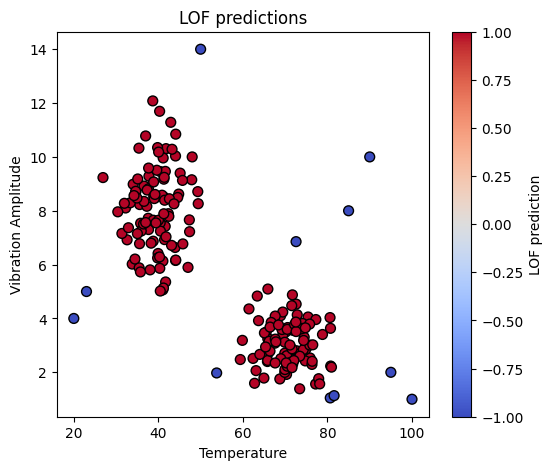

In [ ]:
# Plot the scatter of the data with lof predictions as point color
fig, axes = plt.subplots(1, 1, figsize=(6, 5))

# Plot LOF predictions
scatter_lof_pred = axes.scatter(
    data[:, 0], data[:, 1],
    c=lof_pred, cmap='coolwarm', edgecolor='k', s=50
)
axes.set_title("LOF predictions")
axes.set_xlabel("Temperature")
axes.set_ylabel("Vibration Amplitude")
fig.colorbar(scatter_lof_pred, ax=axes, label='LOF prediction')

 ## Think
  1. what determines the detection outcome here?
  2. How could you change it?
  3. What is the problematic?





### plot LOF scores

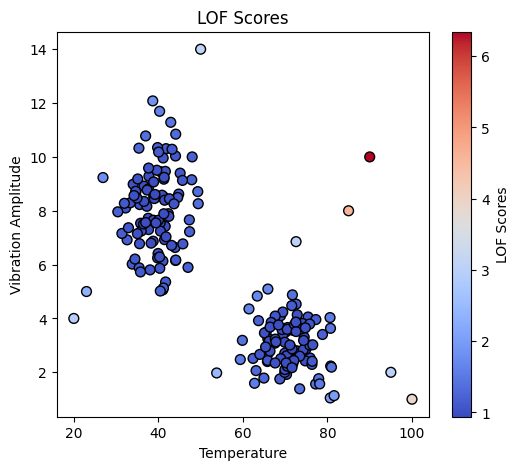

In [ ]:
# Plot the scatter of the data with the lof scores as point color
fig, axes = plt.subplots(1, 1, figsize=(6, 5))

# Plot LOF scores
scatter_lof_scores = axes.scatter(
    data[:, 0], data[:, 1],
    c=lof_scores, cmap='coolwarm', edgecolor='k', s=50
)
axes.set_title("LOF Scores")
axes.set_xlabel("Temperature")
axes.set_ylabel("Vibration Amplitude")
fig.colorbar(scatter_lof_scores, ax=axes, label='LOF Scores')

## Think
1. what is the difference between this and the previous plot?
2. which one is more informative? why?
3. what is missing to finilize the anomaly detection?
4. how would you achieve this?
5. How do the results depend on the choice of hyperparameters?

## Ensemble of LOFs
Since the LOF anomaly scores depend strongly on the model parameters (no. of NNs and assumed contamination ratio), we run an ensemble of models, each with a different NN value and look at statistics of the diffferent predictions.

In [ ]:
# Scale the data - important for better detection
scaler = RobustScaler()
data_scaled = scaler.fit_transform(data)

# Define n_neighbors values
n_neighbors_values = [10, 20, 30, 40, 50, 60, 80, 90, 100, 110, 120, 130,140,150]
# Fix the assumed contamination
contamination_ratio = 0.05

# Initialize an array to store LOF scores for all runs
lof_scores = np.zeros((data_scaled.shape[0], len(n_neighbors_values)))

# Run LOF for each n_neighbors value and store LOF scores
for i, n_neighbors in enumerate(n_neighbors_values):
    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination_ratio)
    lof.fit(data_scaled)  # Fit the model
    lof_scores[:, i] = -lof.negative_outlier_factor_  # Store LOF scores

# Calculate statistics for each data point
mean_scores = np.mean(lof_scores, axis=1)
std_scores = np.std(lof_scores, axis=1)
median_scores = np.median(lof_scores, axis=1)





### plot statistics of the scores

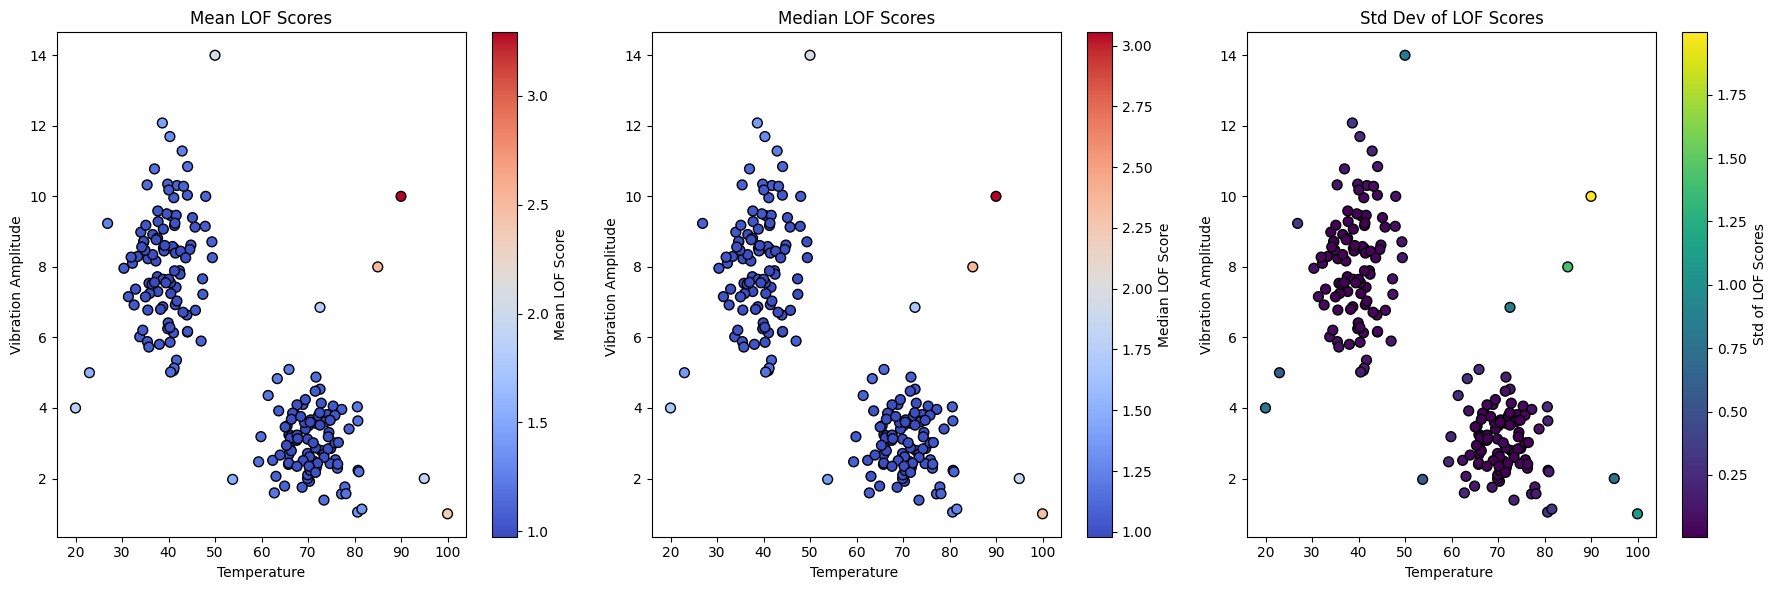

In [ ]:

# Plot the scatter of the data for each statistic
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot mean LOF scores
scatter_mean = axes[0].scatter(
    data[:, 0], data[:, 1],
    c=mean_scores, cmap='coolwarm', edgecolor='k', s=50
)
axes[0].set_title("Mean LOF Scores")
axes[0].set_xlabel("Temperature")
axes[0].set_ylabel("Vibration Amplitude")
fig.colorbar(scatter_mean, ax=axes[0], label='Mean LOF Score')

# Plot median LOF scores
scatter_median = axes[1].scatter(
    data[:, 0], data[:, 1],
    c=median_scores, cmap='coolwarm', edgecolor='k', s=50
)
axes[1].set_title("Median LOF Scores")
axes[1].set_xlabel("Temperature ")
axes[1].set_ylabel("Vibration Amplitude ")
fig.colorbar(scatter_median, ax=axes[1], label='Median LOF Score')

# Plot std deviation of LOF scores
scatter_std = axes[2].scatter(
    data[:, 0], data[:, 1],
    c=std_scores, cmap='viridis', edgecolor='k', s=50
)
axes[2].set_title("Std Dev of LOF Scores")
axes[2].set_xlabel("Temperature ")
axes[2].set_ylabel("Vibration Amplitude")
fig.colorbar(scatter_std, ax=axes[2], label='Std of LOF Scores')

plt.tight_layout()
plt.show()


## Think
1. what is the benefit in running an ensemble?
2. what would be the next step to detect anomalies?

# Detection threshold

In [ ]:
# select which of the scores to use as an anomaly score
anomaly_score = std_scores

# calculate statistics of the score over samples
score_mean =  np.mean(anomaly_score)
score_std = np.std(anomaly_score)

# define threshold for detection
score_threshold = score_mean + 2*score_std

# count how many anomalies are detected
np.sum(anomaly_score > score_threshold)

np.int64(9)

Text(0.5, 0, 'anomaly score')

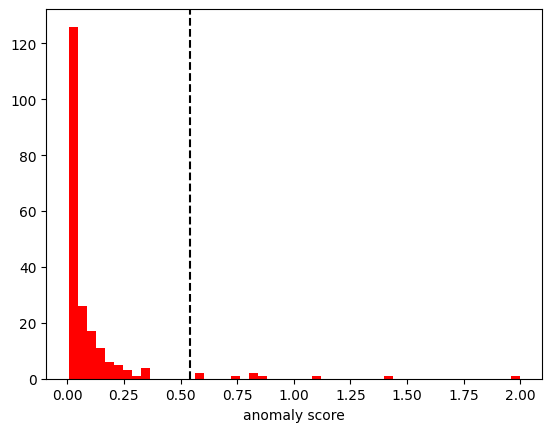

In [ ]:
plt.figure()
plt.hist(anomaly_score,50,color = 'r')
plt.axvline(x=score_threshold, color='k', linestyle='--')
plt.xlabel('anomaly score')

## Detection threshold: robust

In [ ]:
# select which of the scores to use as an anomaly score
anomaly_score = std_scores

# calculate robust statistics of the score over samples
score_median =  np.median(anomaly_score)
score_iqr = np.quantile(anomaly_score,0.95)-np.quantile(anomaly_score,0.05)

# define threshold for detection
score_threshold = score_median + score_iqr

# count how many anomalies are detected
np.sum(anomaly_score > score_threshold)

np.int64(9)

In [ ]:
score_median,score_iqr

(np.float64(0.03012248606530488), np.float64(0.32829244924217477))

## Plot robust threshold

Text(0.5, 0, 'anomaly score')

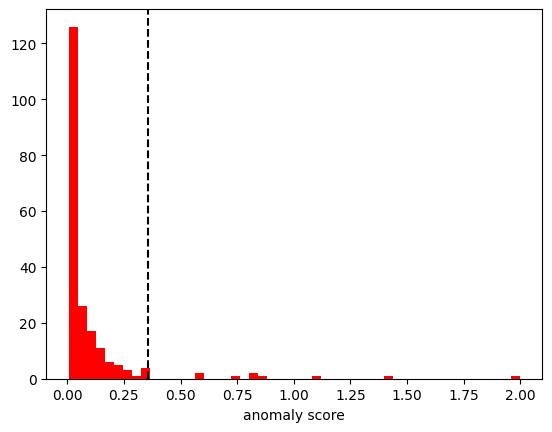

In [ ]:
plt.figure()
plt.hist(anomaly_score,50,color = 'r')
plt.axvline(x=score_threshold, color='k', linestyle='--')
plt.xlabel('anomaly score')

## Think
1. Our selection of the thresholds above was somewhat arbitrary. why?
2. Inspect the distribution of std_scores. Where would you set the threshold?
3. Can you "translate" your intuition into an algorithm?
